<a href="https://colab.research.google.com/github/KruthikaVirupakshappa/DATA266-Lab1-Pair37/blob/jiayi-work/task3_gan/jiayi/src/Task3_CycleGAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import json
from pathlib import Path

MEMBER_NAME = "jiayi"
config_path = Path("task3_gan") / MEMBER_NAME / "config.json"

with open(config_path, "r") as f:
    config = json.load(f)

SID4         = 4253  # last four digits of your SJSU ID
SEED         = config["seed"] # torch.manual_seed, np.random.seed, random_state
SLICE        = SID4 % 1000   # start index of your dataset subset
HP_ID        = SID4 % 6      # your assigned hyperparameter arm, Table 0.1
CLS_A, CLS_B = (SID4 % 10), ((SID4 // 10) % 10)   # your two focus classes

DATA_DIR = Path(config["data"]["data_dir"])
RESIZE_SIZE = config["data"]["resize"]
CROP_SIZE = config["data"]["crop_size"]
RANDOM_HORIZONTAL_FLIP = config["data"]["random_horizontal_flip"]
NORMALIZE_MEAN = tuple(config["data"]["normalize_mean"])
NORMALIZE_STD = tuple(config["data"]["normalize_std"])

BATCH_SIZE = config["dataloader"]["batch_size"]
SHUFFLE = config["dataloader"]["shuffle"]
NUM_WORKERS = config["dataloader"]["num_workers"]
PIN_MEMORY = config["dataloader"]["pin_memory"]
PERSISTENT_WORKERS = config["dataloader"]["persistent_workers"]

INPUT_NC = config["model"]["input_nc"]
OUTPUT_NC = config["model"]["output_nc"]
NGF = config["model"]["ngf"]
NDF = config["model"]["ndf"]
GENERATOR_ARCH = config["model"]["generator"]
DISCRIMINATOR_ARCH = config["model"]["discriminator"]
NORM = config["model"]["norm"]
USE_DROPOUT = config["model"]["use_dropout"]

EPOCHS = config["training"]["epochs"]
GAN_MODE = config["training"]["gan_mode"]
LAMBDA_A = config["training"]["lambda_A"]
LAMBDA_B = config["training"]["lambda_B"]
LEARNING_RATE = config["training"]["learning_rate"]
BETAS = tuple(config["training"]["betas"])
GRAD_LOG_INTERVAL = config["training"]["gradient_log_interval"]
INIT_TYPE = config["model"]["init_type"]
INIT_GAIN = config["model"]["init_gain"]

In [7]:
print(f"SID4: {SID4}, SEED: {SEED}, SLICE: {SLICE}, HP_ID: {HP_ID}, CLS_A, CLS_B: {CLS_A}, {CLS_B}")

SID4: 4253, SEED: 4253, SLICE: 253, HP_ID: 5, CLS_A, CLS_B: 3, 5


### Data Preparation

In [64]:
!pip -q install lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 6.2 MB/s eta 0:00:00


In [89]:
import random
import numpy as np
import torch
from pathlib import Path
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
import math
import torch.nn as nn
import torch.nn.functional as F
import time
import matplotlib.pyplot as plt
from datetime import datetime
import platform
from zoneinfo import ZoneInfo
import subprocess
import sys
from tqdm.auto import tqdm
import re
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from nltk.stem import PorterStemmer
from collections import Counter
from datasets import load_from_disk
from PIL import Image
from torchvision import transforms
import itertools
import shutil
from PIL import Image, ImageDraw
import torchvision.transforms as T
import torchvision.models as models
from tqdm.auto import tqdm
import lpips
from sklearn.metrics import cohen_kappa_score

In [9]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [11]:
monet_dir = DATA_DIR / "monet_jpg"
photo_dir = DATA_DIR / "photo_jpg"

monet_paths = sorted(monet_dir.glob("*.jpg"))
photo_paths = sorted(photo_dir.glob("*.jpg"))

print("Monet images:", len(monet_paths))
print("Photo images:", len(photo_paths))

print("Example Monet:", monet_paths[0])
print("Example Photo:", photo_paths[0])

Monet images: 300
Photo images: 7038
Example Monet: task3_gan/data/monet_jpg/000c1e3bff.jpg
Example Photo: task3_gan/data/photo_jpg/00068bc07f.jpg


In [12]:
monet_img = Image.open(monet_paths[0]).convert("RGB")
photo_img = Image.open(photo_paths[0]).convert("RGB")

print("Monet size:", monet_img.size)
print("Photo size:", photo_img.size)

Monet size: (256, 256)
Photo size: (256, 256)


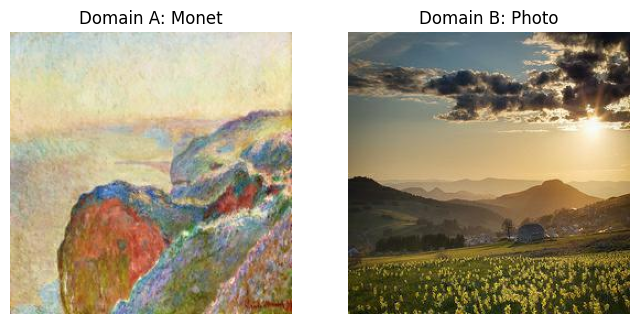

In [13]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(monet_img)
plt.title("Domain A: Monet")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(photo_img)
plt.title("Domain B: Photo")
plt.axis("off")

plt.show()

In [14]:
transform = transforms.Compose([
    transforms.Resize(RESIZE_SIZE),
    transforms.RandomCrop(CROP_SIZE),
    transforms.RandomHorizontalFlip(p=0.5 if RANDOM_HORIZONTAL_FLIP else 0.0),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD)
])

In [15]:
class UnpairedDataset(Dataset):
    def __init__(self, monet_paths, photo_paths, transform=None):
        self.monet_paths = monet_paths
        self.photo_paths = photo_paths
        self.transform = transform

    def __len__(self):
        return max(len(self.monet_paths), len(self.photo_paths))

    def __getitem__(self, idx):
        monet_path = self.monet_paths[idx % len(self.monet_paths)]

        photo_idx = random.randint(0, len(self.photo_paths) - 1)
        photo_path = self.photo_paths[photo_idx]

        monet = Image.open(monet_path).convert("RGB")
        photo = Image.open(photo_path).convert("RGB")

        if self.transform:
            monet = self.transform(monet)
            photo = self.transform(photo)

        return monet, photo

In [16]:
dataset = UnpairedDataset(monet_paths, photo_paths, transform=transform)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=SHUFFLE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    generator=loader_generator
)

In [17]:
real_A, real_B = next(iter(loader))

print("Monet batch:", real_A.shape)
print("Photo batch:", real_B.shape)

Monet batch: torch.Size([2, 3, 256, 256])
Photo batch: torch.Size([2, 3, 256, 256])


### Model

In [18]:
import torch
import torch.nn as nn
from torch.nn import init
import functools
from torch.optim import lr_scheduler


###############################################################################
# Helper Functions
###############################################################################


class Identity(nn.Module):
    def forward(self, x):
        return x


def get_norm_layer(norm_type="instance"):
    """Return a normalization layer

    Parameters:
        norm_type (str) -- the name of the normalization layer: batch | instance | none

    For BatchNorm, we use learnable affine parameters and track running statistics (mean/stddev).
    For InstanceNorm, we do not use learnable affine parameters. We do not track running statistics.
    """
    if norm_type == "batch":
        norm_layer = functools.partial(nn.BatchNorm2d, affine=True, track_running_stats=True)
    elif norm_type == "syncbatch":
        norm_layer = functools.partial(nn.SyncBatchNorm, affine=True, track_running_stats=True)
    elif norm_type == "instance":
        norm_layer = functools.partial(nn.InstanceNorm2d, affine=False, track_running_stats=False)
    elif norm_type == "none":

        def norm_layer(x):
            return Identity()

    else:
        raise NotImplementedError("normalization layer [%s] is not found" % norm_type)
    return norm_layer


def get_scheduler(optimizer, opt):
    """Return a learning rate scheduler

    Parameters:
        optimizer          -- the optimizer of the network
        opt (option class) -- stores all the experiment flags; needs to be a subclass of BaseOptions．
                              opt.lr_policy is the name of learning rate policy: linear | step | plateau | cosine

    For 'linear', we keep the same learning rate for the first <opt.n_epochs> epochs
    and linearly decay the rate to zero over the next <opt.n_epochs_decay> epochs.
    For other schedulers (step, plateau, and cosine), we use the default PyTorch schedulers.
    See https://pytorch.org/docs/stable/optim.html for more details.
    """
    if opt.lr_policy == "linear":

        def lambda_rule(epoch):
            lr_l = 1.0 - max(0, epoch + opt.epoch_count - opt.n_epochs) / float(opt.n_epochs_decay + 1)
            return lr_l

        scheduler = lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda_rule)
    elif opt.lr_policy == "step":
        scheduler = lr_scheduler.StepLR(optimizer, step_size=opt.lr_decay_iters, gamma=0.1)
    elif opt.lr_policy == "plateau":
        scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, threshold=0.01, patience=5)
    elif opt.lr_policy == "cosine":
        scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=opt.n_epochs, eta_min=0)
    else:
        return NotImplementedError("learning rate policy [%s] is not implemented", opt.lr_policy)
    return scheduler


def init_weights(net, init_type="normal", init_gain=0.02):
    """Initialize network weights.

    Parameters:
        net (network)   -- network to be initialized
        init_type (str) -- the name of an initialization method: normal | xavier | kaiming | orthogonal
        init_gain (float)    -- scaling factor for normal, xavier and orthogonal.

    We use 'normal' in the original pix2pix and CycleGAN paper. But xavier and kaiming might
    work better for some applications. Feel free to try yourself.
    """

    def init_func(m):  # define the initialization function
        classname = m.__class__.__name__
        if hasattr(m, "weight") and (classname.find("Conv") != -1 or classname.find("Linear") != -1):
            if init_type == "normal":
                init.normal_(m.weight.data, 0.0, init_gain)
            elif init_type == "xavier":
                init.xavier_normal_(m.weight.data, gain=init_gain)
            elif init_type == "kaiming":
                init.kaiming_normal_(m.weight.data, a=0, mode="fan_in")
            elif init_type == "orthogonal":
                init.orthogonal_(m.weight.data, gain=init_gain)
            else:
                raise NotImplementedError("initialization method [%s] is not implemented" % init_type)
            if hasattr(m, "bias") and m.bias is not None:
                init.constant_(m.bias.data, 0.0)
        elif classname.find("BatchNorm2d") != -1:  # BatchNorm Layer's weight is not a matrix; only normal distribution applies.
            init.normal_(m.weight.data, 1.0, init_gain)
            init.constant_(m.bias.data, 0.0)

    print("initialize network with %s" % init_type)
    net.apply(init_func)  # apply the initialization function <init_func>


def init_net(net, init_type="normal", init_gain=0.02):
    """Initialize a network: 1. register CPU/GPU device; 2. initialize the network weights
    Parameters:
        net (network)      -- the network to be initialized
        init_type (str)    -- the name of an initialization method: normal | xavier | kaiming | orthogonal
        gain (float)       -- scaling factor for normal, xavier and orthogonal.

    Return an initialized network.
    """
    import os

    if torch.cuda.is_available():
        if "LOCAL_RANK" in os.environ:
            local_rank = int(os.environ["LOCAL_RANK"])
            net.to(local_rank)
            print(f"Initialized with device cuda:{local_rank}")
        else:
            net.to(0)
            print("Initialized with device cuda:0")
    init_weights(net, init_type, init_gain=init_gain)
    return net


def define_G(input_nc, output_nc, ngf, netG, norm="batch", use_dropout=False, init_type="normal", init_gain=0.02):
    """Create a generator

    Parameters:
        input_nc (int) -- the number of channels in input images
        output_nc (int) -- the number of channels in output images
        ngf (int) -- the number of filters in the last conv layer
        netG (str) -- the architecture's name: resnet_9blocks | resnet_6blocks | unet_128 | unet_256
        norm (str) -- the name of normalization layers used in the network: batch | instance | none
        use_dropout (bool) -- if use dropout layers.
        init_type (str)    -- the name of our initialization method.
        init_gain (float)  -- scaling factor for normal, xavier and orthogonal.

    Returns a generator
    """
    net = None
    norm_layer = get_norm_layer(norm_type=norm)

    if netG == "resnet_9blocks":
        net = ResnetGenerator(input_nc, output_nc, ngf, norm_layer=norm_layer, use_dropout=use_dropout, n_blocks=9)
    elif netG == "resnet_6blocks":
        net = ResnetGenerator(input_nc, output_nc, ngf, norm_layer=norm_layer, use_dropout=use_dropout, n_blocks=6)
    elif netG == "unet_128":
        net = UnetGenerator(input_nc, output_nc, 7, ngf, norm_layer=norm_layer, use_dropout=use_dropout)
    elif netG == "unet_256":
        net = UnetGenerator(input_nc, output_nc, 8, ngf, norm_layer=norm_layer, use_dropout=use_dropout)
    else:
        raise NotImplementedError("Generator model name [%s] is not recognized" % netG)
    return net


def define_D(input_nc, ndf, netD, n_layers_D=3, norm="batch", init_type="normal", init_gain=0.02):
    """Create a discriminator

    Parameters:
        input_nc (int)     -- the number of channels in input images
        ndf (int)          -- the number of filters in the first conv layer
        netD (str)         -- the architecture's name: basic | n_layers | pixel
        n_layers_D (int)   -- the number of conv layers in the discriminator; effective when netD=='n_layers'
        norm (str)         -- the type of normalization layers used in the network.
        init_type (str)    -- the name of the initialization method.
        init_gain (float)  -- scaling factor for normal, xavier and orthogonal.

    Returns a discriminator

    Our current implementation provides three types of discriminators:
        [basic]: 'PatchGAN' classifier described in the original pix2pix paper.
        It can classify whether 70×70 overlapping patches are real or fake.
        Such a patch-level discriminator architecture has fewer parameters
        than a full-image discriminator and can work on arbitrarily-sized images
        in a fully convolutional fashion.

        [n_layers]: With this mode, you can specify the number of conv layers in the discriminator
        with the parameter <n_layers_D> (default=3 as used in [basic] (PatchGAN).)

        [pixel]: 1x1 PixelGAN discriminator can classify whether a pixel is real or not.
        It encourages greater color diversity but has no effect on spatial statistics.

    The discriminator has been initialized by <init_net>. It uses Leakly RELU for non-linearity.
    """
    net = None
    norm_layer = get_norm_layer(norm_type=norm)

    if netD == "basic":  # default PatchGAN classifier
        net = NLayerDiscriminator(input_nc, ndf, n_layers=3, norm_layer=norm_layer)
    elif netD == "n_layers":  # more options
        net = NLayerDiscriminator(input_nc, ndf, n_layers_D, norm_layer=norm_layer)
    elif netD == "pixel":  # classify if each pixel is real or fake
        net = PixelDiscriminator(input_nc, ndf, norm_layer=norm_layer)
    else:
        raise NotImplementedError("Discriminator model name [%s] is not recognized" % netD)
    return net


##############################################################################
# Classes
##############################################################################
class GANLoss(nn.Module):
    """Define different GAN objectives.

    The GANLoss class abstracts away the need to create the target label tensor
    that has the same size as the input.
    """

    def __init__(self, gan_mode, target_real_label=1.0, target_fake_label=0.0):
        """Initialize the GANLoss class.

        Parameters:
            gan_mode (str) - - the type of GAN objective. It currently supports vanilla, lsgan, and wgangp.
            target_real_label (bool) - - label for a real image
            target_fake_label (bool) - - label of a fake image

        Note: Do not use sigmoid as the last layer of Discriminator.
        LSGAN needs no sigmoid. vanilla GANs will handle it with BCEWithLogitsLoss.
        """
        super(GANLoss, self).__init__()
        self.register_buffer("real_label", torch.tensor(target_real_label))
        self.register_buffer("fake_label", torch.tensor(target_fake_label))
        self.gan_mode = gan_mode
        if gan_mode == "lsgan":
            self.loss = nn.MSELoss()
        elif gan_mode == "vanilla":
            self.loss = nn.BCEWithLogitsLoss()
        elif gan_mode in ["wgangp"]:
            self.loss = None
        else:
            raise NotImplementedError("gan mode %s not implemented" % gan_mode)

    def get_target_tensor(self, prediction, target_is_real):
        """Create label tensors with the same size as the input.

        Parameters:
            prediction (tensor) - - tpyically the prediction from a discriminator
            target_is_real (bool) - - if the ground truth label is for real images or fake images

        Returns:
            A label tensor filled with ground truth label, and with the size of the input
        """

        if target_is_real:
            target_tensor = self.real_label
        else:
            target_tensor = self.fake_label
        return target_tensor.expand_as(prediction)

    def __call__(self, prediction, target_is_real):
        """Calculate loss given Discriminator's output and grount truth labels.

        Parameters:
            prediction (tensor) - - tpyically the prediction output from a discriminator
            target_is_real (bool) - - if the ground truth label is for real images or fake images

        Returns:
            the calculated loss.
        """
        if self.gan_mode in ["lsgan", "vanilla"]:
            target_tensor = self.get_target_tensor(prediction, target_is_real)
            loss = self.loss(prediction, target_tensor)
        elif self.gan_mode == "wgangp":
            if target_is_real:
                loss = -prediction.mean()
            else:
                loss = prediction.mean()
        return loss


def cal_gradient_penalty(netD, real_data, fake_data, device, type="mixed", constant=1.0, lambda_gp=10.0):
    """Calculate the gradient penalty loss, used in WGAN-GP paper https://arxiv.org/abs/1704.00028

    Arguments:
        netD (network)              -- discriminator network
        real_data (tensor array)    -- real images
        fake_data (tensor array)    -- generated images from the generator
        device (str)                -- GPU / CPU
        type (str)                  -- if we mix real and fake data or not [real | fake | mixed].
        constant (float)            -- the constant used in formula ( ||gradient||_2 - constant)^2
        lambda_gp (float)           -- weight for this loss

    Returns the gradient penalty loss
    """
    if lambda_gp > 0.0:
        if type == "real":  # either use real images, fake images, or a linear interpolation of two.
            interpolatesv = real_data
        elif type == "fake":
            interpolatesv = fake_data
        elif type == "mixed":
            alpha = torch.rand(real_data.shape[0], 1, device=device)
            alpha = alpha.expand(real_data.shape[0], real_data.nelement() // real_data.shape[0]).contiguous().view(*real_data.shape)
            interpolatesv = alpha * real_data + ((1 - alpha) * fake_data)
        else:
            raise NotImplementedError(f"{type} not implemented")
        interpolatesv.requires_grad_(True)
        disc_interpolates = netD(interpolatesv)
        gradients = torch.autograd.grad(outputs=disc_interpolates, inputs=interpolatesv, grad_outputs=torch.ones(disc_interpolates.size()).to(device), create_graph=True, retain_graph=True, only_inputs=True)
        gradients = gradients[0].view(real_data.size(0), -1)  # flat the data
        gradient_penalty = (((gradients + 1e-16).norm(2, dim=1) - constant) ** 2).mean() * lambda_gp  # added eps
        return gradient_penalty, gradients
    else:
        return 0.0, None


class ResnetGenerator(nn.Module):
    """Resnet-based generator that consists of Resnet blocks between a few downsampling/upsampling operations.

    We adapt Torch code and idea from Justin Johnson's neural style transfer project(https://github.com/jcjohnson/fast-neural-style)
    """

    def __init__(self, input_nc, output_nc, ngf=64, norm_layer=nn.BatchNorm2d, use_dropout=False, n_blocks=6, padding_type="reflect"):
        """Construct a Resnet-based generator

        Parameters:
            input_nc (int)      -- the number of channels in input images
            output_nc (int)     -- the number of channels in output images
            ngf (int)           -- the number of filters in the last conv layer
            norm_layer          -- normalization layer
            use_dropout (bool)  -- if use dropout layers
            n_blocks (int)      -- the number of ResNet blocks
            padding_type (str)  -- the name of padding layer in conv layers: reflect | replicate | zero
        """
        assert n_blocks >= 0
        super(ResnetGenerator, self).__init__()
        if type(norm_layer) == functools.partial:
            use_bias = norm_layer.func == nn.InstanceNorm2d
        else:
            use_bias = norm_layer == nn.InstanceNorm2d

        model = [nn.ReflectionPad2d(3), nn.Conv2d(input_nc, ngf, kernel_size=7, padding=0, bias=use_bias), norm_layer(ngf), nn.ReLU(True)]

        n_downsampling = 2
        for i in range(n_downsampling):  # add downsampling layers
            mult = 2**i
            model += [nn.Conv2d(ngf * mult, ngf * mult * 2, kernel_size=3, stride=2, padding=1, bias=use_bias), norm_layer(ngf * mult * 2), nn.ReLU(True)]

        mult = 2**n_downsampling
        for i in range(n_blocks):  # add ResNet blocks

            model += [ResnetBlock(ngf * mult, padding_type=padding_type, norm_layer=norm_layer, use_dropout=use_dropout, use_bias=use_bias)]

        for i in range(n_downsampling):  # add upsampling layers
            mult = 2 ** (n_downsampling - i)
            model += [nn.ConvTranspose2d(ngf * mult, int(ngf * mult / 2), kernel_size=3, stride=2, padding=1, output_padding=1, bias=use_bias), norm_layer(int(ngf * mult / 2)), nn.ReLU(True)]
        model += [nn.ReflectionPad2d(3)]
        model += [nn.Conv2d(ngf, output_nc, kernel_size=7, padding=0)]
        model += [nn.Tanh()]

        self.model = nn.Sequential(*model)

    def forward(self, input):
        """Standard forward"""
        return self.model(input)


class ResnetBlock(nn.Module):
    """Define a Resnet block"""

    def __init__(self, dim, padding_type, norm_layer, use_dropout, use_bias):
        """Initialize the Resnet block

        A resnet block is a conv block with skip connections
        We construct a conv block with build_conv_block function,
        and implement skip connections in <forward> function.
        Original Resnet paper: https://arxiv.org/pdf/1512.03385.pdf
        """
        super(ResnetBlock, self).__init__()
        self.conv_block = self.build_conv_block(dim, padding_type, norm_layer, use_dropout, use_bias)

    def build_conv_block(self, dim, padding_type, norm_layer, use_dropout, use_bias):
        """Construct a convolutional block.

        Parameters:
            dim (int)           -- the number of channels in the conv layer.
            padding_type (str)  -- the name of padding layer: reflect | replicate | zero
            norm_layer          -- normalization layer
            use_dropout (bool)  -- if use dropout layers.
            use_bias (bool)     -- if the conv layer uses bias or not

        Returns a conv block (with a conv layer, a normalization layer, and a non-linearity layer (ReLU))
        """
        conv_block = []
        p = 0
        if padding_type == "reflect":
            conv_block += [nn.ReflectionPad2d(1)]
        elif padding_type == "replicate":
            conv_block += [nn.ReplicationPad2d(1)]
        elif padding_type == "zero":
            p = 1
        else:
            raise NotImplementedError("padding [%s] is not implemented" % padding_type)

        conv_block += [nn.Conv2d(dim, dim, kernel_size=3, padding=p, bias=use_bias), norm_layer(dim), nn.ReLU(True)]
        if use_dropout:
            conv_block += [nn.Dropout(0.5)]

        p = 0
        if padding_type == "reflect":
            conv_block += [nn.ReflectionPad2d(1)]
        elif padding_type == "replicate":
            conv_block += [nn.ReplicationPad2d(1)]
        elif padding_type == "zero":
            p = 1
        else:
            raise NotImplementedError("padding [%s] is not implemented" % padding_type)
        conv_block += [nn.Conv2d(dim, dim, kernel_size=3, padding=p, bias=use_bias), norm_layer(dim)]

        return nn.Sequential(*conv_block)

    def forward(self, x):
        """Forward function (with skip connections)"""
        out = x + self.conv_block(x)  # add skip connections
        return out


class UnetGenerator(nn.Module):
    """Create a Unet-based generator"""

    def __init__(self, input_nc, output_nc, num_downs, ngf=64, norm_layer=nn.BatchNorm2d, use_dropout=False):
        """Construct a Unet generator
        Parameters:
            input_nc (int)  -- the number of channels in input images
            output_nc (int) -- the number of channels in output images
            num_downs (int) -- the number of downsamplings in UNet. For example, # if |num_downs| == 7,
                                image of size 128x128 will become of size 1x1 # at the bottleneck
            ngf (int)       -- the number of filters in the last conv layer
            norm_layer      -- normalization layer

        We construct the U-Net from the innermost layer to the outermost layer.
        It is a recursive process.
        """
        super(UnetGenerator, self).__init__()
        # construct unet structure
        unet_block = UnetSkipConnectionBlock(ngf * 8, ngf * 8, input_nc=None, submodule=None, norm_layer=norm_layer, innermost=True)  # add the innermost layer
        for i in range(num_downs - 5):  # add intermediate layers with ngf * 8 filters
            unet_block = UnetSkipConnectionBlock(ngf * 8, ngf * 8, input_nc=None, submodule=unet_block, norm_layer=norm_layer, use_dropout=use_dropout)
        # gradually reduce the number of filters from ngf * 8 to ngf
        unet_block = UnetSkipConnectionBlock(ngf * 4, ngf * 8, input_nc=None, submodule=unet_block, norm_layer=norm_layer)
        unet_block = UnetSkipConnectionBlock(ngf * 2, ngf * 4, input_nc=None, submodule=unet_block, norm_layer=norm_layer)
        unet_block = UnetSkipConnectionBlock(ngf, ngf * 2, input_nc=None, submodule=unet_block, norm_layer=norm_layer)
        self.model = UnetSkipConnectionBlock(output_nc, ngf, input_nc=input_nc, submodule=unet_block, outermost=True, norm_layer=norm_layer)  # add the outermost layer

    def forward(self, input):
        """Standard forward"""
        return self.model(input)


class UnetSkipConnectionBlock(nn.Module):
    """Defines the Unet submodule with skip connection.
    X -------------------identity----------------------
    |-- downsampling -- |submodule| -- upsampling --|
    """

    def __init__(self, outer_nc, inner_nc, input_nc=None, submodule=None, outermost=False, innermost=False, norm_layer=nn.BatchNorm2d, use_dropout=False):
        """Construct a Unet submodule with skip connections.

        Parameters:
            outer_nc (int) -- the number of filters in the outer conv layer
            inner_nc (int) -- the number of filters in the inner conv layer
            input_nc (int) -- the number of channels in input images/features
            submodule (UnetSkipConnectionBlock) -- previously defined submodules
            outermost (bool)    -- if this module is the outermost module
            innermost (bool)    -- if this module is the innermost module
            norm_layer          -- normalization layer
            use_dropout (bool)  -- if use dropout layers.
        """
        super(UnetSkipConnectionBlock, self).__init__()
        self.outermost = outermost
        if type(norm_layer) == functools.partial:
            use_bias = norm_layer.func == nn.InstanceNorm2d
        else:
            use_bias = norm_layer == nn.InstanceNorm2d
        if input_nc is None:
            input_nc = outer_nc
        downconv = nn.Conv2d(input_nc, inner_nc, kernel_size=4, stride=2, padding=1, bias=use_bias)
        downrelu = nn.LeakyReLU(0.2, True)
        downnorm = norm_layer(inner_nc)
        uprelu = nn.ReLU(True)
        upnorm = norm_layer(outer_nc)

        if outermost:
            upconv = nn.ConvTranspose2d(inner_nc * 2, outer_nc, kernel_size=4, stride=2, padding=1)
            down = [downconv]
            up = [uprelu, upconv, nn.Tanh()]
            model = down + [submodule] + up
        elif innermost:
            upconv = nn.ConvTranspose2d(inner_nc, outer_nc, kernel_size=4, stride=2, padding=1, bias=use_bias)
            down = [downrelu, downconv]
            up = [uprelu, upconv, upnorm]
            model = down + up
        else:
            upconv = nn.ConvTranspose2d(inner_nc * 2, outer_nc, kernel_size=4, stride=2, padding=1, bias=use_bias)
            down = [downrelu, downconv, downnorm]
            up = [uprelu, upconv, upnorm]

            if use_dropout:
                model = down + [submodule] + up + [nn.Dropout(0.5)]
            else:
                model = down + [submodule] + up

        self.model = nn.Sequential(*model)

    def forward(self, x):
        if self.outermost:
            return self.model(x)
        else:  # add skip connections
            return torch.cat([x, self.model(x)], 1)


class NLayerDiscriminator(nn.Module):
    """Defines a PatchGAN discriminator"""

    def __init__(self, input_nc, ndf=64, n_layers=3, norm_layer=nn.BatchNorm2d):
        """Construct a PatchGAN discriminator

        Parameters:
            input_nc (int)  -- the number of channels in input images
            ndf (int)       -- the number of filters in the last conv layer
            n_layers (int)  -- the number of conv layers in the discriminator
            norm_layer      -- normalization layer
        """
        super(NLayerDiscriminator, self).__init__()
        if type(norm_layer) == functools.partial:  # no need to use bias as BatchNorm2d has affine parameters
            use_bias = norm_layer.func == nn.InstanceNorm2d
        else:
            use_bias = norm_layer == nn.InstanceNorm2d

        kw = 4
        padw = 1
        sequence = [nn.Conv2d(input_nc, ndf, kernel_size=kw, stride=2, padding=padw), nn.LeakyReLU(0.2, True)]
        nf_mult = 1
        nf_mult_prev = 1
        for n in range(1, n_layers):  # gradually increase the number of filters
            nf_mult_prev = nf_mult
            nf_mult = min(2**n, 8)
            sequence += [nn.Conv2d(ndf * nf_mult_prev, ndf * nf_mult, kernel_size=kw, stride=2, padding=padw, bias=use_bias), norm_layer(ndf * nf_mult), nn.LeakyReLU(0.2, True)]

        nf_mult_prev = nf_mult
        nf_mult = min(2**n_layers, 8)
        sequence += [nn.Conv2d(ndf * nf_mult_prev, ndf * nf_mult, kernel_size=kw, stride=1, padding=padw, bias=use_bias), norm_layer(ndf * nf_mult), nn.LeakyReLU(0.2, True)]

        sequence += [nn.Conv2d(ndf * nf_mult, 1, kernel_size=kw, stride=1, padding=padw)]  # output 1 channel prediction map
        self.model = nn.Sequential(*sequence)

    def forward(self, input):
        """Standard forward."""
        return self.model(input)


class PixelDiscriminator(nn.Module):
    """Defines a 1x1 PatchGAN discriminator (pixelGAN)"""

    def __init__(self, input_nc, ndf=64, norm_layer=nn.BatchNorm2d):
        """Construct a 1x1 PatchGAN discriminator

        Parameters:
            input_nc (int)  -- the number of channels in input images
            ndf (int)       -- the number of filters in the last conv layer
            norm_layer      -- normalization layer
        """
        super(PixelDiscriminator, self).__init__()
        if type(norm_layer) == functools.partial:  # no need to use bias as BatchNorm2d has affine parameters
            use_bias = norm_layer.func == nn.InstanceNorm2d
        else:
            use_bias = norm_layer == nn.InstanceNorm2d

        self.net = [
            nn.Conv2d(input_nc, ndf, kernel_size=1, stride=1, padding=0),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf, ndf * 2, kernel_size=1, stride=1, padding=0, bias=use_bias),
            norm_layer(ndf * 2),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf * 2, 1, kernel_size=1, stride=1, padding=0, bias=use_bias),
        ]

        self.net = nn.Sequential(*self.net)

    def forward(self, input):
        """Standard forward."""
        return self.net(input)

In [19]:
# set randomness for the run
set_seed(SEED)
loader_generator.manual_seed(SEED)

netG_A = define_G(INPUT_NC, OUTPUT_NC, NGF, GENERATOR_ARCH, norm=NORM, use_dropout=USE_DROPOUT, init_type=INIT_TYPE, init_gain=INIT_GAIN).to(device)
netG_B = define_G(INPUT_NC, OUTPUT_NC, NGF, GENERATOR_ARCH, norm=NORM, use_dropout=USE_DROPOUT, init_type=INIT_TYPE, init_gain=INIT_GAIN).to(device)
netD_A = define_D(OUTPUT_NC, NDF, DISCRIMINATOR_ARCH, norm=NORM, init_type=INIT_TYPE, init_gain=INIT_GAIN).to(device)
netD_B = define_D(INPUT_NC, NDF, DISCRIMINATOR_ARCH, norm=NORM, init_type=INIT_TYPE, init_gain=INIT_GAIN).to(device)


In [21]:
criterion_GAN = GANLoss(GAN_MODE).to(device)
criterion_cycle = nn.L1Loss()

lambda_A = LAMBDA_A
lambda_B = LAMBDA_B

optimizer_G = torch.optim.Adam(itertools.chain(netG_A.parameters(), netG_B.parameters()), lr=LEARNING_RATE, betas=BETAS)
optimizer_D = torch.optim.Adam(itertools.chain(netD_A.parameters(), netD_B.parameters()), lr=LEARNING_RATE, betas=BETAS)

In [22]:
def set_requires_grad(nets, requires_grad):
    for net in nets:
        for param in net.parameters(): param.requires_grad = requires_grad

def get_grad_stats(parameters):
    grads = [p.grad.detach() for p in parameters if p.grad is not None]
    if not grads: return 0.0, 0
    total_norm = torch.norm(torch.stack([g.norm(2) for g in grads]), 2).item()
    nan_count = int(torch.stack([torch.isnan(g).sum() for g in grads]).sum().item())
    return total_norm, nan_count

In [24]:
# log run setup
output_dir = Path("task3_gan") / MEMBER_NAME / "outputs"; output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir = Path("task3_gan") / MEMBER_NAME / "checkpoints"; checkpoint_dir.mkdir(parents=True, exist_ok=True)
log_dir = Path("reproducibility/raw_logs"); log_dir.mkdir(parents=True, exist_ok=True)
manifest_dir = Path("reproducibility/manifests"); manifest_dir.mkdir(parents=True, exist_ok=True)

LA_TZ = ZoneInfo("America/Los_Angeles")
run_timestamp = datetime.now(LA_TZ).strftime("%Y%m%d_%H%M%S")
train_log_path = log_dir / f"task3_{MEMBER_NAME}_cyclegan_train_{run_timestamp}.log"
environment_path = manifest_dir / f"task3_{MEMBER_NAME}_cyclegan_environment_{run_timestamp}.txt"
final_checkpoint_path = checkpoint_dir / f"task3_cyclegan_final_{run_timestamp}.pt"
generator_loss_curve_path = output_dir / f"cyclegan_generator_cycle_losses_{run_timestamp}.png"
discriminator_loss_curve_path = output_dir / f"cyclegan_discriminator_losses_{run_timestamp}.png"

with open(environment_path, "w") as f: subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=f, text=True, check=True)
log_file = open(train_log_path, "x", encoding="utf-8")

def log(message):
    timestamp = datetime.now(LA_TZ).strftime("%Y-%m-%d %H:%M:%S %Z")
    line = f"[{timestamp}] {message}"
    print(line); log_file.write(line + "\n"); log_file.flush()

def get_cpu_name():
    try:
        result = subprocess.run(["lscpu"], capture_output=True, text=True, check=True)
        for line in result.stdout.splitlines():
            if line.startswith("Model name:"): return line.split(":", 1)[1].strip()
    except Exception: pass
    return platform.processor() or platform.machine()

cpu_name = get_cpu_name()
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU"
g_params = list(itertools.chain(netG_A.parameters(), netG_B.parameters()))
d_params = list(itertools.chain(netD_A.parameters(), netD_B.parameters()))
g_parameter_count = sum(p.numel() for p in g_params); d_parameter_count = sum(p.numel() for p in d_params); parameter_count = g_parameter_count + d_parameter_count

log("Task 3 CycleGAN Official Training")
log(f"Config file: {config_path}")
log(f"Config: {json.dumps(config, sort_keys=True)}")
log(f"Seed: {SEED}")
log(f"Device: {device}, CPU: {cpu_name}, GPU: {gpu_name}")
log(f"Python: {platform.python_version()}, PyTorch: {torch.__version__}, CUDA: {torch.version.cuda}")
log(f"Environment file: {environment_path}")
log(f"Monet images: {len(monet_paths)}, Photo images: {len(photo_paths)}, Training pairs/epoch: {len(dataset)}")
log(f"Generator: {GENERATOR_ARCH}, Discriminator: {DISCRIMINATOR_ARCH}, NGF: {NGF}, NDF: {NDF}, Norm: {NORM}, Dropout: {USE_DROPOUT}")
log(f"Weight initialization: {INIT_TYPE}, init gain: {INIT_GAIN}")
log(f"GAN loss: {GAN_MODE}, Cycle loss: L1, Lambda A/B: {lambda_A}/{lambda_B}, Identity loss used: {config['training']['identity_loss']}, Lambda identity: {config['training']['lambda_identity']}")
log(f"Optimizer: {config['training']['optimizer']}, LR: {LEARNING_RATE}, Betas: {BETAS}, LR scheduler: {config['training']['lr_scheduler']}, Image pool: {config['training']['image_pool']}")
log(f"Batch size: {BATCH_SIZE}, Epochs: {EPOCHS}, Gradient log interval: {GRAD_LOG_INTERVAL} batches")
log(f"Parameters: G={g_parameter_count}, D={d_parameter_count}, Total={parameter_count}")

[2026-10-04 02:12:22 PDT] Task 3 CycleGAN Official Training
[2026-10-04 02:12:22 PDT] Config file: task3_gan/jiayi/config.json
[2026-10-04 02:12:22 PDT] Config: {"data": {"crop_size": 256, "data_dir": "task3_gan/data", "normalize_mean": [0.5, 0.5, 0.5], "normalize_std": [0.5, 0.5, 0.5], "random_horizontal_flip": true, "resize": 286}, "dataloader": {"batch_size": 2, "num_workers": 2, "persistent_workers": true, "pin_memory": true, "shuffle": true}, "model": {"discriminator": "basic", "generator": "resnet_6blocks", "init_gain": 0.02, "init_type": "normal", "input_nc": 3, "ndf": 64, "ngf": 64, "norm": "instance", "output_nc": 3, "use_dropout": false}, "seed": 4253, "training": {"betas": [0.5, 0.999], "epochs": 10, "gan_mode": "lsgan", "gradient_log_interval": 100, "identity_loss": false, "image_pool": false, "lambda_A": 10.0, "lambda_B": 10.0, "lambda_identity": 0.0, "learning_rate": 0.0001, "lr_scheduler": "none", "optimizer": "Adam"}}
[2026-10-04 02:12:22 PDT] Seed: 4253
[2026-10-04 02:

In [25]:
num_epochs = EPOCHS
history = {"G": [], "D_A": [], "D_B": [], "cycle_A": [], "cycle_B": []}
grad_history = {"G": [], "D": []}
total_pairs = 0; total_train_seconds = 0.0; total_loss_nan_count = 0; total_grad_nan_count = 0

if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
run_start = time.perf_counter()

for epoch in range(num_epochs):
    netG_A.train(); netG_B.train(); netD_A.train(); netD_B.train()
    sums = {k: 0.0 for k in history}; num_batches = 0; epoch_pairs = 0
    sampled_g_norms = []; sampled_d_norms = []; epoch_grad_nan_count = 0; epoch_loss_nan_count = 0
    if device.type == "cuda": torch.cuda.synchronize()
    epoch_start = time.perf_counter()

    for batch_idx, (real_A, real_B) in enumerate(tqdm(loader, desc=f"Epoch {epoch+1}/{num_epochs}")):
        real_A, real_B = real_A.to(device, non_blocking=True), real_B.to(device, non_blocking=True)

        fake_B = netG_A(real_A); rec_A = netG_B(fake_B)
        fake_A = netG_B(real_B); rec_B = netG_A(fake_A)

        set_requires_grad([netD_A, netD_B], False)
        optimizer_G.zero_grad()

        loss_G_A = criterion_GAN(netD_A(fake_B), True)
        loss_G_B = criterion_GAN(netD_B(fake_A), True)
        loss_cycle_A = criterion_cycle(rec_A, real_A) * lambda_A
        loss_cycle_B = criterion_cycle(rec_B, real_B) * lambda_B
        loss_G = loss_G_A + loss_G_B + loss_cycle_A + loss_cycle_B

        loss_G.backward()
        sample_grads = (batch_idx + 1) % GRAD_LOG_INTERVAL == 0 or batch_idx == len(loader) - 1
        if sample_grads:
            g_norm, g_nan = get_grad_stats(g_params); sampled_g_norms.append(g_norm); epoch_grad_nan_count += g_nan
        optimizer_G.step()

        set_requires_grad([netD_A, netD_B], True)
        optimizer_D.zero_grad()

        loss_D_A_real = criterion_GAN(netD_A(real_B), True)
        loss_D_A_fake = criterion_GAN(netD_A(fake_B.detach()), False)
        loss_D_A = 0.5 * (loss_D_A_real + loss_D_A_fake)

        loss_D_B_real = criterion_GAN(netD_B(real_A), True)
        loss_D_B_fake = criterion_GAN(netD_B(fake_A.detach()), False)
        loss_D_B = 0.5 * (loss_D_B_real + loss_D_B_fake)

        loss_D = loss_D_A + loss_D_B
        loss_D.backward()
        if sample_grads:
            d_norm, d_nan = get_grad_stats(d_params); sampled_d_norms.append(d_norm); epoch_grad_nan_count += d_nan
        optimizer_D.step()

        values = [loss_G.item(), loss_D_A.item(), loss_D_B.item(), loss_cycle_A.item(), loss_cycle_B.item()]
        sums["G"] += values[0]; sums["D_A"] += values[1]; sums["D_B"] += values[2]; sums["cycle_A"] += values[3]; sums["cycle_B"] += values[4]
        epoch_loss_nan_count += sum(not math.isfinite(v) for v in values)
        epoch_pairs += real_A.size(0); num_batches += 1

    if device.type == "cuda": torch.cuda.synchronize()
    epoch_seconds = time.perf_counter() - epoch_start
    for k in history: history[k].append(sums[k] / num_batches)
    avg_g_grad = float(np.mean(sampled_g_norms)) if sampled_g_norms else 0.0; avg_d_grad = float(np.mean(sampled_d_norms)) if sampled_d_norms else 0.0
    grad_history["G"].append(avg_g_grad); grad_history["D"].append(avg_d_grad)
    total_pairs += epoch_pairs; total_train_seconds += epoch_seconds; total_loss_nan_count += epoch_loss_nan_count; total_grad_nan_count += epoch_grad_nan_count
    log(f"Epoch {epoch+1}/{num_epochs}, G={history['G'][-1]:.4f}, D_A={history['D_A'][-1]:.4f}, D_B={history['D_B'][-1]:.4f}, Cycle_A={history['cycle_A'][-1]:.4f}, Cycle_B={history['cycle_B'][-1]:.4f}, G_grad_norm={avg_g_grad:.4f}, D_grad_norm={avg_d_grad:.4f}, Loss_NaNs={epoch_loss_nan_count}, Sampled_Grad_NaNs={epoch_grad_nan_count}, Time={epoch_seconds:.2f}s, Images/s={(2 * epoch_pairs / epoch_seconds):.2f}")

if device.type == "cuda": torch.cuda.synchronize(); peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
else: peak_memory_mb = 0.0

total_run_time = time.perf_counter() - run_start
overall_pairs_per_sec = total_pairs / total_train_seconds
overall_images_per_sec = 2 * total_pairs / total_train_seconds

torch.save({"run_id": run_timestamp, "epoch": num_epochs, "netG_A": netG_A.state_dict(), "netG_B": netG_B.state_dict(), "netD_A": netD_A.state_dict(), "netD_B": netD_B.state_dict(), "optimizer_G": optimizer_G.state_dict(), "optimizer_D": optimizer_D.state_dict(), "history": history, "grad_history": grad_history, "config": config, "parameter_count": parameter_count}, final_checkpoint_path)

log(f"Total Training Time: {total_train_seconds:.2f} s")
log(f"Total Run Time: {total_run_time:.2f} s")
log(f"Overall Pairs/s: {overall_pairs_per_sec:.2f}, Overall Images/s: {overall_images_per_sec:.2f}")
log(f"Peak GPU Memory: {peak_memory_mb:.2f} MB")
log(f"Total Loss NaN Count: {total_loss_nan_count}, Total Sampled Gradient NaN Count: {total_grad_nan_count}")
log(f"Final checkpoint: {final_checkpoint_path}")
log("Training completed successfully.")
log_file.close()

Epoch 1/10:   0%|          | 0/3519 [00:00<?, ?it/s]

[2026-10-04 02:17:53 PDT] Epoch 1/10, G=5.1999, D_A=0.1848, D_B=0.1809, Cycle_A=2.0480, Cycle_B=2.1866, G_grad_norm=56.7843, D_grad_norm=13.0309, Loss_NaNs=0, Sampled_Grad_NaNs=0, Time=243.45s, Images/s=57.82


Epoch 2/10:   0%|          | 0/3519 [00:00<?, ?it/s]

[2026-10-04 02:21:54 PDT] Epoch 2/10, G=4.3697, D_A=0.1795, D_B=0.1761, Cycle_A=1.6864, Cycle_B=1.7269, G_grad_norm=43.4910, D_grad_norm=11.7778, Loss_NaNs=0, Sampled_Grad_NaNs=0, Time=241.34s, Images/s=58.32


Epoch 3/10:   0%|          | 0/3519 [00:00<?, ?it/s]

...

[2026-10-04 02:46:04 PDT] Epoch 8/10, G=3.3717, D_A=0.1698, D_B=0.1505, Cycle_A=1.0586, Cycle_B=1.2597, G_grad_norm=35.4780, D_grad_norm=11.2423, Loss_NaNs=0, Sampled_Grad_NaNs=0, Time=240.16s, Images/s=58.61


Epoch 9/10:   0%|          | 0/3519 [00:00<?, ?it/s]

[2026-10-04 02:50:04 PDT] Epoch 9/10, G=3.2988, D_A=0.1709, D_B=0.1404, Cycle_A=1.0107, Cycle_B=1.2124, G_grad_norm=33.5341, D_grad_norm=11.1826, Loss_NaNs=0, Sampled_Grad_NaNs=0, Time=240.05s, Images/s=58.64


Epoch 10/10:   0%|          | 0/3519 [00:00<?, ?it/s]

[2026-10-04 02:54:05 PDT] Epoch 10/10, G=3.3377, D_A=0.1668, D_B=0.1104, Cycle_A=0.9787, Cycle_B=1.1875, G_grad_norm=33.1625, D_grad_norm=10.3497, Loss_NaNs=0, Sampled_Grad_NaNs=0, Time=241.58s, Images/s=58.27
[2026-10-04 02:54:05 PDT] Total Training Time: 2415.55 s
[2026-10-04 02:54:05 PDT] Total Run Time: 2415.56 s
[2026-10-04 02:54:05 PDT] Overall Pairs/s: 29.14, Overall Images/s: 58.27
[2026-10-04 02:54:05 PDT] Peak GPU Memory: 2562.60 MB
[2026-10-04 02:54:05 PDT] Total Loss NaN Count: 0, Total Sampled Gradient NaN Count: 0
[2026-10-04 02:54:05 PDT] Final checkpoint: task3_gan/jiayi/checkpoints/task3_cyclegan_final_20261004_021221.pt
[2026-10-04 02:54:05 PDT] Training completed successfully.


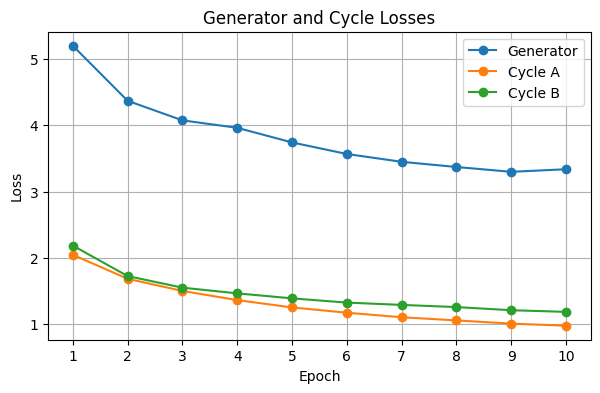

Saved generator/cycle loss curve: task3_gan/jiayi/outputs/cyclegan_generator_cycle_losses_20261004_021221.png


In [26]:
epochs = range(1, len(history["G"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["G"], marker="o", label="Generator")
plt.plot(epochs, history["cycle_A"], marker="o", label="Cycle A")
plt.plot(epochs, history["cycle_B"], marker="o", label="Cycle B")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Generator and Cycle Losses"); plt.xticks(epochs); plt.legend(); plt.grid()
plt.savefig(generator_loss_curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved generator/cycle loss curve:", generator_loss_curve_path)

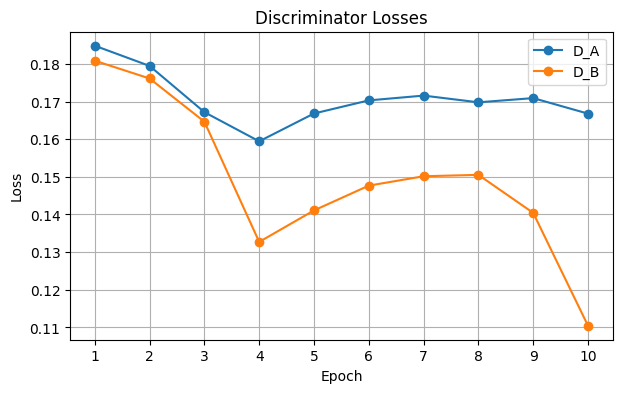

Saved discriminator loss curve: task3_gan/jiayi/outputs/cyclegan_discriminator_losses_20261004_021221.png


In [27]:
plt.figure(figsize=(7, 4))
plt.plot(epochs, history["D_A"], marker="o", label="D_A")
plt.plot(epochs, history["D_B"], marker="o", label="D_B")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Discriminator Losses"); plt.xticks(epochs); plt.legend(); plt.grid()
plt.savefig(discriminator_loss_curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved discriminator loss curve:", discriminator_loss_curve_path)

In [28]:
manifest = {
    "task": "task3_gan",
    "model": "cyclegan_resnet6_patchgan",
    "member": MEMBER_NAME,
    "run_id": run_timestamp,
    "config_file": str(config_path),
    "config": config,
    "raw_log": str(train_log_path),
    "final_checkpoint": str(final_checkpoint_path),
    "checkpoint_result_mapping": {
        "checkpoint": str(final_checkpoint_path),
        "training_results": [str(generator_loss_curve_path), str(discriminator_loss_curve_path)],
        "downstream_evaluation": "Use this checkpoint for Task 3 evaluation metrics and generated outputs."
    },
    "loss_curves": {"generator_cycle": str(generator_loss_curve_path), "discriminator": str(discriminator_loss_curve_path)},
    "cpu": cpu_name,
    "gpu": gpu_name,
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "parameter_count": {"generators": g_parameter_count, "discriminators": d_parameter_count, "total": parameter_count},
    "training_time_sec": total_train_seconds,
    "total_run_time_sec": total_run_time,
    "pairs_per_sec": overall_pairs_per_sec,
    "images_per_sec": overall_images_per_sec,
    "peak_gpu_memory_mb": peak_memory_mb,
    "gradient_norm_mean": {"G": float(np.mean(grad_history["G"])), "D": float(np.mean(grad_history["D"]))},
    "loss_nan_count": total_loss_nan_count,
    "sampled_gradient_nan_count": total_grad_nan_count,
    "identity_loss": {"used": config["training"]["identity_loss"], "lambda": config["training"]["lambda_identity"]},
    "environment_file": str(environment_path),
    "metrics_report": str(Path("task3_gan") / MEMBER_NAME / "metrics_report.csv")
}

manifest_path = manifest_dir / f"task3_{MEMBER_NAME}_cyclegan_manifest_{run_timestamp}.json"
with open(manifest_path, "w") as f: json.dump(manifest, f, indent=2)

print("Saved raw log:", train_log_path)
print("Saved checkpoint:", final_checkpoint_path)
print("Saved loss curves:", generator_loss_curve_path, discriminator_loss_curve_path)
print("Saved manifest:", manifest_path)
print("Saved environment:", environment_path)

Saved raw log: reproducibility/raw_logs/task3_jiayi_cyclegan_train_20261004_021221.log
Saved checkpoint: task3_gan/jiayi/checkpoints/task3_cyclegan_final_20261004_021221.pt
Saved loss curves: task3_gan/jiayi/outputs/cyclegan_generator_cycle_losses_20261004_021221.png task3_gan/jiayi/outputs/cyclegan_discriminator_losses_20261004_021221.png
Saved manifest: reproducibility/manifests/task3_jiayi_cyclegan_manifest_20261004_021221.json
Saved environment: reproducibility/manifests/task3_jiayi_cyclegan_environment_20261004_021221.txt


In [29]:
def show_img(x):
    x = x.detach().cpu().squeeze(0)
    x = (x + 1) / 2
    return x.permute(1, 2, 0).clamp(0, 1)

In [30]:
real_A, real_B = next(iter(loader))
real_A, real_B = real_A[:1].to(device), real_B[:1].to(device)

netG_A.eval(); netG_B.eval()

with torch.no_grad():
    fake_B = netG_A(real_A)
    rec_A = netG_B(fake_B)
    fake_A = netG_B(real_B)
    rec_B = netG_A(fake_A)

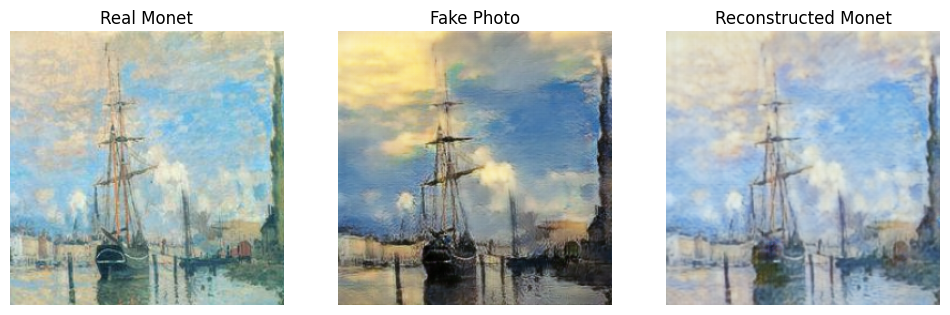

In [31]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1); plt.imshow(show_img(real_A)); plt.title("Real Monet"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(show_img(fake_B)); plt.title("Fake Photo"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(show_img(rec_A)); plt.title("Reconstructed Monet"); plt.axis("off")

plt.show()

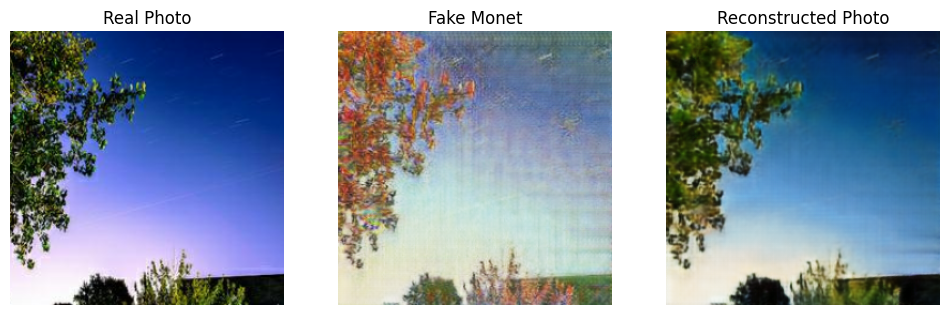

In [32]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1); plt.imshow(show_img(real_B)); plt.title("Real Photo"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(show_img(fake_A)); plt.title("Fake Monet"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(show_img(rec_B)); plt.title("Reconstructed Photo"); plt.axis("off")

plt.show()

### Inference

In [32]:
checkpoint_path = Path(
    "task3_gan/jiayi/checkpoints/task3_cyclegan_final_20261004_021221.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

netG_A = define_G(
    INPUT_NC, OUTPUT_NC, NGF, GENERATOR_ARCH,
    norm=NORM, use_dropout=USE_DROPOUT
).to(device)

netG_B = define_G(
    INPUT_NC, OUTPUT_NC, NGF, GENERATOR_ARCH,
    norm=NORM, use_dropout=USE_DROPOUT
).to(device)

netG_A.load_state_dict(checkpoint["netG_A"])
netG_B.load_state_dict(checkpoint["netG_B"])

netG_A.eval()
netG_B.eval()

print("Loaded:", checkpoint_path)
print("Epoch:", checkpoint["epoch"])

Loaded: task3_gan/jiayi/checkpoints/task3_cyclegan_final_20261004_021221.pt
Epoch: 10


In [34]:
pred_A2B_dir = Path("task3_gan/jiayi/outputs/pred_A2B")
pred_B2A_dir = Path("task3_gan/jiayi/outputs/pred_B2A")

# Remove stale predictions from earlier runs
for folder in [pred_A2B_dir, pred_B2A_dir]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)

# Deterministic inference transform:
# same resize / normalization as training, but no random crop or flip
infer_transform = transforms.Compose([
    transforms.Resize(RESIZE_SIZE),      # 286
    transforms.CenterCrop(CROP_SIZE),    # 256
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
set_seed(SEED)

In [35]:
def generate_predictions(paths, model, output_dir, n=300):
    paths = sorted(paths)[:n]

    with torch.inference_mode():
        for path in tqdm(paths):
            img = Image.open(path).convert("RGB")
            x = infer_transform(img).unsqueeze(0).to(device)

            fake = model(x)[0].cpu()
            fake = ((fake + 1) / 2).clamp(0, 1)

            out = transforms.ToPILImage()(fake).convert("RGB")

            assert out.size == (256, 256)
            assert out.mode == "RGB"

            out.save(output_dir / f"{path.stem}.jpg", format="JPEG", quality=95)

In [36]:
# A = Monet, B = Photo
generate_predictions(monet_paths, netG_A, pred_A2B_dir, n=300)
generate_predictions(photo_paths, netG_B, pred_B2A_dir, n=300)

print("pred_A2B:", len(list(pred_A2B_dir.glob("*.jpg"))))
print("pred_B2A:", len(list(pred_B2A_dir.glob("*.jpg"))))

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

pred_A2B: 300
pred_B2A: 300


## Kaggle evaluation

In [37]:
import os, glob
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torchvision.transforms as T
import torchvision.models as models

import scipy.linalg
from scipy.spatial.distance import cosine

In [38]:
# Config: set root
BASE = "task3_gan"

REAL_MONET = os.path.join(BASE, "data", "monet_jpg")  # real domain B
REAL_PHOTO = os.path.join(BASE, "data", "photo_jpg")  # real domain B
GEN_A2B = os.path.join(BASE, "jiayi", "outputs", "pred_A2B") # Monet -> Photo
GEN_B2A = os.path.join(BASE, "jiayi", "outputs", "pred_B2A") # Photo -> Monet


# Limit to N images per set
# Set to None to use all images in each folder
N_EVAL = 300

BATCH_SIZE = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [39]:
def list_images(folder):
    exts = (".jpg", ".jpeg", ".png")
    paths = []
    for ext in exts:
        paths.extend(glob.glob(os.path.join(folder, f"*{ext}")))
        paths.extend(glob.glob(os.path.join(folder, f"*{ext.upper()}")))
    paths = sorted(list(set(paths)))
    return paths

def take_n(paths, n):
    if n is None:
        return paths
    return paths[:min(n, len(paths))]

In [40]:
# Inception feature extractor
def get_inception_model():
    inception = models.inception_v3(
        weights=models.Inception_V3_Weights.IMAGENET1K_V1,
        transform_input=False
    )
    inception.fc = nn.Identity()
    inception.to(device)
    inception.eval()
    return inception

INCEPTION_TF = T.Compose([
    T.Resize(299),
    T.CenterCrop(299),
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

def load_batch(paths):
    imgs = []
    for p in paths:
        img = Image.open(p).convert("RGB")
        imgs.append(INCEPTION_TF(img))
    return torch.stack(imgs, dim=0)

@torch.no_grad()
def get_activations(model, image_paths, batch_size=32):
    feats = []
    for i in tqdm(range(0, len(image_paths), batch_size), desc="Inception activations"):
        batch_paths = image_paths[i:i+batch_size]
        x = load_batch(batch_paths).to(device)
        f = model(x).detach().cpu().numpy()
        feats.append(f)
    return np.concatenate(feats, axis=0)

In [41]:
def frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = scipy.linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    diff = mu1 - mu2
    return float(diff.dot(diff) + np.trace(sigma1 + sigma2 - 2 * covmean))

In [42]:
def calculate_fid_mifid(real_paths, gen_paths, batch_size=32, subsample_to_match=True):
    # For fair comparison, match counts
    real_paths = sorted(real_paths)
    gen_paths  = sorted(gen_paths)

    if subsample_to_match:
        n = min(len(real_paths), len(gen_paths))
        real_paths = real_paths[:n]
        gen_paths  = gen_paths[:n]

    model = get_inception_model()

    real_act = get_activations(model, real_paths, batch_size=batch_size)
    gen_act  = get_activations(model, gen_paths,  batch_size=batch_size)

    mu_r, sig_r = real_act.mean(axis=0), np.cov(real_act, rowvar=False)
    mu_g, sig_g = gen_act.mean(axis=0),  np.cov(gen_act,  rowvar=False)

    fid = frechet_distance(mu_r, sig_r, mu_g, sig_g)

    # mean cosine distance between feature vectors,
    # paired by index after subsampling/matching
    m = min(len(real_act), len(gen_act))
    cos_dists = [cosine(real_act[i], gen_act[i]) for i in range(m)]
    mifid = float(np.mean(cos_dists))

    return fid, mifid

In [43]:
for d in [REAL_MONET, REAL_PHOTO, GEN_A2B, GEN_B2A]:
    assert os.path.isdir(d), f"Missing folder: {d}"

real_monet = take_n(list_images(REAL_MONET), N_EVAL)
real_photo = take_n(list_images(REAL_PHOTO), N_EVAL)
gen_a2b    = take_n(list_images(GEN_A2B),    N_EVAL)  # Monet->Photo (generated photos)
gen_b2a    = take_n(list_images(GEN_B2A),    N_EVAL)  # Photo->Monet (generated monet)

print("\nCounts (after N_EVAL cap):")
print("Real Monet:", len(real_monet), " | Gen Monet (B2A):", len(gen_b2a))
print("Real Photo:", len(real_photo), " | Gen Photo (A2B):", len(gen_a2b))


Counts (after N_EVAL cap):
Real Monet: 300  | Gen Monet (B2A): 300
Real Photo: 300  | Gen Photo (A2B): 300


In [44]:
print("\n Evaluating Photo -> Monet (B2A) ")
# Ground truth = real Monet; Generated = pred_B2A (generated Monet-like)
fid_B2A, mifid_B2A = calculate_fid_mifid(real_monet, gen_b2a, batch_size=BATCH_SIZE)
print(f"[Photo->Monet] FID={fid_B2A:.3f}  MiFID={mifid_B2A:.4f}")

print("\n Evaluating Monet -> Photo (A2B) ")
# Ground truth = real Photo; Generated = pred_A2B (generated Photo-like)
fid_A2B, mifid_A2B = calculate_fid_mifid(real_photo, gen_a2b, batch_size=BATCH_SIZE)
print(f"[Monet->Photo] FID={fid_A2B:.3f}  MiFID={mifid_A2B:.4f}")



 Evaluating Photo -> Monet (B2A) 
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 193MB/s] 
Inception activations: 100%|██████████| 10/10 [00:01<00:00,  6.67it/s]
/tmp/ipykernel_1490/2390798440.py:2: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


[Photo->Monet] FID=108.709  MiFID=0.4099

 Evaluating Monet -> Photo (A2B) 


Inception activations: 100%|██████████| 10/10 [00:01<00:00,  7.82it/s]


[Monet->Photo] FID=107.579  MiFID=0.4237


In [45]:
import pandas as pd

sub_fid  = (fid_A2B + fid_B2A) / 2
sub_mifid = (mifid_A2B + mifid_B2A) / 2

submission = pd.DataFrame([{
    "ID": 1,
    "FID": float(sub_fid),
    "MiFID": float(sub_mifid)}])

submission_path = "task3_gan/jiayi/submission.csv"
submission.to_csv(submission_path, index=False)
print(submission)

   ID         FID    MiFID
0   1  108.143975  0.41682


### Human Audit Preparation

In [53]:
a2b_generated = sorted(pred_A2B_dir.glob("*.jpg"))
b2a_generated = sorted(pred_B2A_dir.glob("*.jpg"))

assert all((monet_dir / p.name).exists() for p in a2b_generated)
assert all((photo_dir / p.name).exists() for p in b2a_generated)

print("A2B mappings:", len(a2b_generated))
print("B2A mappings:", len(b2a_generated))
print("All source mappings verified.")

A2B mappings: 300
B2A mappings: 300
All source mappings verified.


In [54]:
audit_dir = Path("task3_gan/jiayi/outputs/human_audit")
audit_dir.mkdir(parents=True, exist_ok=True)

rng = random.Random(SEED)

a2b_files = sorted(pred_A2B_dir.glob("*.jpg"))
b2a_files = sorted(pred_B2A_dir.glob("*.jpg"))

audit_a2b = rng.sample(a2b_files, 15)
audit_b2a = rng.sample(b2a_files, 15)

In [55]:
rows = []

for i, gen_path in enumerate(audit_a2b, start=1):
    rows.append({
        "sample_id": f"S{i:02d}",
        "direction": "Monet_to_Photo",
        "source_path": str(monet_dir / gen_path.name),
        "generated_path": str(gen_path),
    })

for i, gen_path in enumerate(audit_b2a, start=16):
    rows.append({
        "sample_id": f"S{i:02d}",
        "direction": "Photo_to_Monet",
        "source_path": str(photo_dir / gen_path.name),
        "generated_path": str(gen_path),
    })

audit_mapping = pd.DataFrame(rows)

audit_mapping.to_csv(
    audit_dir / "human_audit_samples.csv",
    index=False
)

audit_mapping.head()

,sample_id,direction,source_path,generated_path
0,S01,Monet_to_Photo,task3_gan/data/monet_jpg/fc11d52502.jpg,task3_gan/jiayi/outputs/pred_A2B/fc11d52502.jpg
1,S02,Monet_to_Photo,task3_gan/data/monet_jpg/695897bd4a.jpg,task3_gan/jiayi/outputs/pred_A2B/695897bd4a.jpg
2,S03,Monet_to_Photo,task3_gan/data/monet_jpg/f0884db067.jpg,task3_gan/jiayi/outputs/pred_A2B/f0884db067.jpg
3,S04,Monet_to_Photo,task3_gan/data/monet_jpg/99d94af5dd.jpg,task3_gan/jiayi/outputs/pred_A2B/99d94af5dd.jpg
4,S05,Monet_to_Photo,task3_gan/data/monet_jpg/05144e306f.jpg,task3_gan/jiayi/outputs/pred_A2B/05144e306f.jpg


In [56]:
for row in rows:
    source = Image.open(row["source_path"]).convert("RGB").resize((256, 256))
    generated = Image.open(row["generated_path"]).convert("RGB")

    canvas = Image.new("RGB", (512, 290), "white")
    canvas.paste(source, (0, 34))
    canvas.paste(generated, (256, 34))

    draw = ImageDraw.Draw(canvas)

    draw.text((10, 8), "Input", fill="black")
    draw.text((266, 8), "Generated", fill="black")

    canvas.save(
        audit_dir / f'{row["sample_id"]}.jpg',
        quality=95
    )

### Calculate human rating

In [85]:
ratings = pd.read_csv(
    "task3_gan/jiayi/outputs/human_audit_ratings_raw_20261004_021221.csv",
    skiprows=1
)

ratings.head()

,sample_id,direction,rater_id,style,content,artifacts,notes
0,S01,Monet_to_Photo,R1,2,4,4,NaN
1,S01,Monet_to_Photo,R2,1,4,3,NaN
2,S02,Monet_to_Photo,R1,2,4,3,NaN
3,S02,Monet_to_Photo,R2,1,4,2,NaN
4,S03,Monet_to_Photo,R1,1,4,3,NaN


In [86]:
human_summary = (
    ratings
    .groupby("direction")[["style", "content", "artifacts"]]
    .mean()
)

print(human_summary)

                   style   content  artifacts
direction                                    
Monet_to_Photo  1.666667  3.500000   3.000000
Photo_to_Monet  3.866667  3.833333   3.266667


In [87]:
audit_a2b = human_summary.loc["Monet_to_Photo"].mean()
audit_b2a = human_summary.loc["Photo_to_Monet"].mean()

audit_overall = ratings[
    ["style", "content", "artifacts"]
].to_numpy().mean()

print("A2B human audit:", audit_a2b)
print("B2A human audit:", audit_b2a)
print("Overall human audit:", audit_overall)

A2B human audit: 2.7222222222222228
B2A human audit: 3.6555555555555554
Overall human audit: 3.188888888888889


In [90]:
r1 = ratings[ratings["rater_id"] == "R1"].sort_values("sample_id")
r2 = ratings[ratings["rater_id"] == "R2"].sort_values("sample_id")

assert r1["sample_id"].tolist() == r2["sample_id"].tolist()

kappa_style = cohen_kappa_score(
    r1["style"],
    r2["style"],
    weights="quadratic"
)

kappa_content = cohen_kappa_score(
    r1["content"],
    r2["content"],
    weights="quadratic"
)

kappa_artifacts = cohen_kappa_score(
    r1["artifacts"],
    r2["artifacts"],
    weights="quadratic"
)

kappa_overall = np.mean([
    kappa_style,
    kappa_content,
    kappa_artifacts
])

print("Style kappa:", kappa_style)
print("Content kappa:", kappa_content)
print("Artifacts kappa:", kappa_artifacts)
print("Mean kappa:", kappa_overall)

Style kappa: 0.8820887142055025
Content kappa: 0.38144329896907214
Artifacts kappa: 0.3571428571428571
Mean kappa: 0.5402249567724772


In [91]:
human_metrics = {
    "HumanStyle_A2B":
        human_summary.loc["Monet_to_Photo", "style"],

    "HumanContent_A2B":
        human_summary.loc["Monet_to_Photo", "content"],

    "HumanArtifacts_A2B":
        human_summary.loc["Monet_to_Photo", "artifacts"],

    "HumanStyle_B2A":
        human_summary.loc["Photo_to_Monet", "style"],

    "HumanContent_B2A":
        human_summary.loc["Photo_to_Monet", "content"],

    "HumanArtifacts_B2A":
        human_summary.loc["Photo_to_Monet", "artifacts"],

    "HumanAudit_A2B": audit_a2b,
    "HumanAudit_B2A": audit_b2a,
    "HumanAudit_Overall": audit_overall,

    "Kappa_Style": kappa_style,
    "Kappa_Content": kappa_content,
    "Kappa_Artifacts": kappa_artifacts,
    "Kappa_Overall": kappa_overall,
}

### Additional Evaluation Metrics

In [61]:
real_monet_paths = sorted(monet_dir.glob("*.jpg"))[:300]
real_photo_paths = sorted(photo_dir.glob("*.jpg"))[:300]

gen_a2b_paths = sorted(pred_A2B_dir.glob("*.jpg"))
gen_b2a_paths = sorted(pred_B2A_dir.glob("*.jpg"))

assert len(gen_a2b_paths) == 300
assert len(gen_b2a_paths) == 300

# Exact source images for each generated image
src_a2b_paths = [monet_dir / p.name for p in gen_a2b_paths]
src_b2a_paths = [photo_dir / p.name for p in gen_b2a_paths]

assert all(p.exists() for p in src_a2b_paths)
assert all(p.exists() for p in src_b2a_paths)

inception = models.inception_v3(
    weights=models.Inception_V3_Weights.IMAGENET1K_V1,
    transform_input=False
)
inception.fc = torch.nn.Identity()
inception = inception.to(device).eval()

INCEPTION_TF = T.Compose([
    T.Resize(299),
    T.CenterCrop(299),
    T.ToTensor(),
    T.Normalize(
        (0.485, 0.456, 0.406),
        (0.229, 0.224, 0.225)
    )
])

# Reconstruct the exact deterministic geometry used as CycleGAN input
SOURCE_GEOM_TF = T.Compose([
    T.Resize(RESIZE_SIZE),   # 286
    T.CenterCrop(CROP_SIZE)  # 256
])

In [62]:
@torch.no_grad()
def extract_features(paths, source_input=False, batch_size=32):
    features = []

    for i in tqdm(range(0, len(paths), batch_size)):
        batch = []

        for path in paths[i:i + batch_size]:
            img = Image.open(path).convert("RGB")

            if source_input:
                img = SOURCE_GEOM_TF(img)

            batch.append(INCEPTION_TF(img))

        x = torch.stack(batch).to(device)
        features.append(inception(x).cpu())

    return torch.cat(features).numpy()

In [63]:
feat_real_monet = extract_features(real_monet_paths)
feat_real_photo = extract_features(real_photo_paths)

feat_a2b = extract_features(gen_a2b_paths)  # generated Photo
feat_b2a = extract_features(gen_b2a_paths)  # generated Monet

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

### KID

In [65]:
def kid_mmd2(x, y):
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)

    d = x.shape[1]

    k_xx = (x @ x.T / d + 1.0) ** 3
    k_yy = (y @ y.T / d + 1.0) ** 3
    k_xy = (x @ y.T / d + 1.0) ** 3

    n, m = len(x), len(y)

    xx = (k_xx.sum() - np.trace(k_xx)) / (n * (n - 1))
    yy = (k_yy.sum() - np.trace(k_yy)) / (m * (m - 1))
    xy = k_xy.mean()

    return xx + yy - 2 * xy


def calculate_kid(real_feat, gen_feat,
                  subset_size=100,
                  n_subsets=100,
                  seed=SEED):

    rng = np.random.default_rng(seed)
    subset_size = min(subset_size, len(real_feat), len(gen_feat))

    values = []

    for _ in range(n_subsets):
        r_idx = rng.choice(len(real_feat), subset_size, replace=False)
        g_idx = rng.choice(len(gen_feat), subset_size, replace=False)

        values.append(
            kid_mmd2(real_feat[r_idx], gen_feat[g_idx])
        )

    return float(np.mean(values)), float(np.std(values))

In [66]:
kid_a2b, kid_a2b_std = calculate_kid(
    feat_real_photo, feat_a2b
)

kid_b2a, kid_b2a_std = calculate_kid(
    feat_real_monet, feat_b2a
)

print(f"A2B KID: {kid_a2b:.6f} ± {kid_a2b_std:.6f}")
print(f"B2A KID: {kid_b2a:.6f} ± {kid_b2a_std:.6f}")

A2B KID: 0.022096 ± 0.002738
B2A KID: 0.012398 ± 0.001745


### Generative precision and recall

In [67]:
def generative_precision_recall(real_feat, gen_feat, k=3):
    real = torch.tensor(real_feat, dtype=torch.float32)
    gen = torch.tensor(gen_feat, dtype=torch.float32)

    # k-NN radii inside each manifold
    d_real = torch.cdist(real, real)
    d_gen = torch.cdist(gen, gen)

    d_real.fill_diagonal_(float("inf"))
    d_gen.fill_diagonal_(float("inf"))

    real_radius = d_real.kthvalue(k, dim=1).values
    gen_radius = d_gen.kthvalue(k, dim=1).values

    cross = torch.cdist(gen, real)

    # Generated point lies inside at least one real-data neighborhood
    precision = (
        cross <= real_radius.unsqueeze(0)
    ).any(dim=1).float().mean()

    # Real point lies inside at least one generated-data neighborhood
    recall = (
        cross <= gen_radius.unsqueeze(1)
    ).any(dim=0).float().mean()

    return float(precision), float(recall)

In [68]:
precision_a2b, recall_a2b = generative_precision_recall(
    feat_real_photo, feat_a2b, k=3
)

precision_b2a, recall_b2a = generative_precision_recall(
    feat_real_monet, feat_b2a, k=3
)

print(f"A2B Precision: {precision_a2b:.4f}")
print(f"A2B Recall:    {recall_a2b:.4f}")

print(f"B2A Precision: {precision_b2a:.4f}")
print(f"B2A Recall:    {recall_b2a:.4f}")

A2B Precision: 0.6200
A2B Recall:    0.3067
B2A Precision: 0.3467
B2A Recall:    0.6533


### Content-preservation cosine similarity

In [69]:
feat_src_a2b = extract_features(
    src_a2b_paths,
    source_input=True
)

feat_src_b2a = extract_features(
    src_b2a_paths,
    source_input=True
)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

In [70]:
def mean_cosine_similarity(x, y):
    x = torch.tensor(x, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)

    scores = F.cosine_similarity(x, y, dim=1)

    return float(scores.mean()), float(scores.std())

In [71]:
cosine_a2b, cosine_a2b_std = mean_cosine_similarity(
    feat_src_a2b, feat_a2b
)

cosine_b2a, cosine_b2a_std = mean_cosine_similarity(
    feat_src_b2a, feat_b2a
)

print(f"A2B cosine: {cosine_a2b:.4f} ± {cosine_a2b_std:.4f}")
print(f"B2A cosine: {cosine_b2a:.4f} ± {cosine_b2a_std:.4f}")

A2B cosine: 0.8022 ± 0.0705
B2A cosine: 0.7624 ± 0.0904


### LPIPS

In [72]:
lpips_model = lpips.LPIPS(
    net="alex",
    verbose=False
).to(device).eval()

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 216MB/s]


In [73]:
SOURCE_LPIPS_TF = T.Compose([
    T.Resize(RESIZE_SIZE),
    T.CenterCrop(CROP_SIZE),
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5),
                (0.5, 0.5, 0.5))
])

GEN_LPIPS_TF = T.Compose([
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5),
                (0.5, 0.5, 0.5))
])

In [74]:
@torch.no_grad()
def calculate_lpips(source_paths, generated_paths, batch_size=32):
    values = []

    for i in tqdm(range(0, len(source_paths), batch_size)):
        src_batch = []
        gen_batch = []

        for src_path, gen_path in zip(
            source_paths[i:i + batch_size],
            generated_paths[i:i + batch_size]
        ):
            src = Image.open(src_path).convert("RGB")
            gen = Image.open(gen_path).convert("RGB")

            src_batch.append(SOURCE_LPIPS_TF(src))
            gen_batch.append(GEN_LPIPS_TF(gen))

        src_batch = torch.stack(src_batch).to(device)
        gen_batch = torch.stack(gen_batch).to(device)

        d = lpips_model(src_batch, gen_batch)
        values.extend(d.view(-1).cpu().numpy())

    values = np.asarray(values)

    return float(values.mean()), float(values.std())

In [75]:
lpips_a2b, lpips_a2b_std = calculate_lpips(
    src_a2b_paths,
    gen_a2b_paths
)

lpips_b2a, lpips_b2a_std = calculate_lpips(
    src_b2a_paths,
    gen_b2a_paths
)

print(f"A2B LPIPS: {lpips_a2b:.4f} ± {lpips_a2b_std:.4f}")
print(f"B2A LPIPS: {lpips_b2a:.4f} ± {lpips_b2a_std:.4f}")

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

A2B LPIPS: 0.3775 ± 0.0811
B2A LPIPS: 0.4370 ± 0.1036


In [76]:
additional_metrics = {
    "KID_A2B": kid_a2b,
    "KID_A2B_std": kid_a2b_std,
    "KID_B2A": kid_b2a,
    "KID_B2A_std": kid_b2a_std,

    "Precision_A2B": precision_a2b,
    "Recall_A2B": recall_a2b,
    "Precision_B2A": precision_b2a,
    "Recall_B2A": recall_b2a,

    "LPIPS_A2B": lpips_a2b,
    "LPIPS_A2B_std": lpips_a2b_std,
    "LPIPS_B2A": lpips_b2a,
    "LPIPS_B2A_std": lpips_b2a_std,

    "Cosine_A2B": cosine_a2b,
    "Cosine_A2B_std": cosine_a2b_std,
    "Cosine_B2A": cosine_b2a,
    "Cosine_B2A_std": cosine_b2a_std,
}

pd.DataFrame(
    additional_metrics.items(),
    columns=["metric", "value"]
)

,metric,value
0,KID_A2B,0.022096
1,KID_A2B_std,0.002738
2,KID_B2A,0.012398
3,KID_B2A_std,0.001745
4,Precision_A2B,0.620000
5,Recall_A2B,0.306667
6,Precision_B2A,0.346667
7,Recall_B2A,0.653333
8,LPIPS_A2B,0.377540
9,LPIPS_A2B_std,0.081123


### Cycle-reconstruction L1 distance

In [78]:
netG_A.eval()
netG_B.eval()

ResnetGenerator(
  (model): Sequential(
    (0): ReflectionPad2d((3, 3, 3, 3))
    (1): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1))
    (2): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (8): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (9): ReLU(inplace=True)
    (10): ResnetBlock(
      (conv_block): Sequential(
        (0): ReflectionPad2d((1, 1, 1, 1))
        (1): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
        (2): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
        (3): ReLU(inplace=True)
        (4): ReflectionPad2d((1, 1, 1, 1))
     

In [79]:
cycle_transform = transforms.Compose([
    transforms.Resize(RESIZE_SIZE),      # 286
    transforms.CenterCrop(CROP_SIZE),    # 256
    transforms.ToTensor(),
    transforms.Normalize(
        NORMALIZE_MEAN,
        NORMALIZE_STD
    )
])

In [80]:
@torch.inference_mode()
def calculate_cycle_l1(paths, first_G, second_G, batch_size=16):
    losses = []

    paths = sorted(paths)[:300]

    for i in tqdm(range(0, len(paths), batch_size)):
        batch = []

        for path in paths[i:i + batch_size]:
            img = Image.open(path).convert("RGB")
            batch.append(cycle_transform(img))

        x = torch.stack(batch).to(device)

        fake = first_G(x)
        reconstructed = second_G(fake)

        # raw cycle L1 before multiplying by lambda=10
        l1_per_image = torch.abs(reconstructed - x).mean(
            dim=(1, 2, 3)
        )

        losses.extend(l1_per_image.cpu().numpy())

    losses = np.asarray(losses)

    return float(losses.mean()), float(losses.std())

In [81]:
cycle_l1_A, cycle_l1_A_std = calculate_cycle_l1(
    monet_paths,
    netG_A,
    netG_B
)

  0%|          | 0/19 [00:00<?, ?it/s]

In [82]:
cycle_l1_B, cycle_l1_B_std = calculate_cycle_l1(
    photo_paths,
    netG_B,
    netG_A
)

  0%|          | 0/19 [00:00<?, ?it/s]

In [83]:
print(
    f"A -> B -> A cycle L1: "
    f"{cycle_l1_A:.6f} ± {cycle_l1_A_std:.6f}"
)

print(
    f"B -> A -> B cycle L1: "
    f"{cycle_l1_B:.6f} ± {cycle_l1_B_std:.6f}"
)

A -> B -> A cycle L1: 0.093340 ± 0.018017
B -> A -> B cycle L1: 0.113932 ± 0.044666


### Full Metrics Report